# Practical 6 - Statistical Tests (t-test, ANOVA, Chi-square, Correlation)
Dataset: Students Performance (1000 students, exam scores and background)

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

HERE = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
def find_data(name):
    """Look for the CSV in the usual places; in Colab, ask for an upload if it is missing."""
    folders = (HERE.parent / "Datasets", HERE / "Datasets", HERE, Path.cwd(),
               Path("/content"), Path("/content/Datasets"), Path("/content/drive/MyDrive"))
    for folder in folders:
        if (folder / name).exists():
            return folder
    try:
        from google.colab import files
        print(f"{name} not found - please choose it in the upload dialog (it is in the Datasets folder).")
        files.upload()
        return Path.cwd()
    except ImportError:
        raise FileNotFoundError(f"Could not find {name}. Put it in a 'Datasets' folder next to this script.")

DATA = find_data("StudentsPerformance.csv")
FIG = HERE / "figures"
FIG.mkdir(exist_ok=True)

ALPHA = 0.05
students = pd.read_csv(DATA / "StudentsPerformance.csv")
students.columns = [c.replace(" ", "_").replace("/", "_") for c in students.columns]
print("Shape  :", students.shape)
print("Columns:", list(students.columns))

def fmt_p(p):
    return "< 1e-300" if p == 0 else f"{p:.3e}"

def verdict(p, yes, no):
    return f"REJECT H0 -> {yes}" if p < ALPHA else f"FAIL TO REJECT H0 -> {no}"

Shape  : (1000, 8)
Columns: ['gender', 'race_ethnicity', 'parental_level_of_education', 'lunch', 'test_preparation_course', 'math_score', 'reading_score', 'writing_score']


## Q1. Independent-samples t-test
Does completing the test-preparation course change the writing score?

Completed course : mean = 74.419  (n = 358)
No course        : mean = 64.505  (n = 642)
t statistic      : 10.7525
p-value          : 2.663e-25
Cohen's d        : 0.698
Decision         : REJECT H0 -> the course is linked to different writing scores


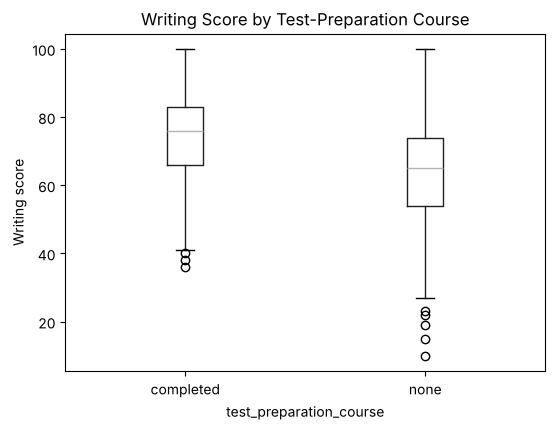

In [2]:
prep = students.loc[students["test_preparation_course"] == "completed", "writing_score"]
noprep = students.loc[students["test_preparation_course"] == "none", "writing_score"]
t_stat, p1 = stats.ttest_ind(prep, noprep, equal_var=False)
pooled_sd = np.sqrt((prep.var() + noprep.var()) / 2)
cohen_d = (prep.mean() - noprep.mean()) / pooled_sd

print(f"Completed course : mean = {prep.mean():.3f}  (n = {len(prep)})")
print(f"No course        : mean = {noprep.mean():.3f}  (n = {len(noprep)})")
print(f"t statistic      : {t_stat:.4f}")
print(f"p-value          : {p1:.3e}")
print(f"Cohen's d        : {cohen_d:.3f}")
print("Decision         :", verdict(p1, "the course is linked to different writing scores", "no evidence of a difference"))

students.boxplot(column="writing_score", by="test_preparation_course", figsize=(6, 4.5), grid=False)
plt.suptitle("")
plt.title("Writing Score by Test-Preparation Course")
plt.ylabel("Writing score")
plt.savefig(FIG / "box_writing_by_prep.png", dpi=120, bbox_inches="tight")
plt.show()

## Q2. One-way ANOVA
Does the average reading score differ between the five ethnic groups?

In [3]:
groups = {name: part["reading_score"] for name, part in students.groupby("race_ethnicity")}
for name, vals in groups.items():
    print(f"{name:<8}: mean = {vals.mean():.3f}  (n = {len(vals)})")

f_stat, p2 = stats.f_oneway(*groups.values())
grand = students["reading_score"].mean()
ss_between = sum(len(v) * (v.mean() - grand) ** 2 for v in groups.values())
ss_total = ((students["reading_score"] - grand) ** 2).sum()
print(f"\nF statistic      : {f_stat:.4f}")
print(f"p-value          : {p2:.3e}")
print(f"Eta squared      : {ss_between / ss_total:.4f}")
print("Decision         :", verdict(p2, "at least one group mean differs", "group means are similar"))

group A : mean = 64.674  (n = 89)
group B : mean = 67.353  (n = 190)
group C : mean = 69.103  (n = 319)
group D : mean = 70.031  (n = 262)
group E : mean = 73.029  (n = 140)

F statistic      : 5.6217
p-value          : 1.780e-04
Eta squared      : 0.0221
Decision         : REJECT H0 -> at least one group mean differs


Pairs significantly different after Tukey HSD (p < 0.05):
  group A vs group D: p = 0.0219
  group A vs group E: p = 0.0002
  group B vs group E: p = 0.0041


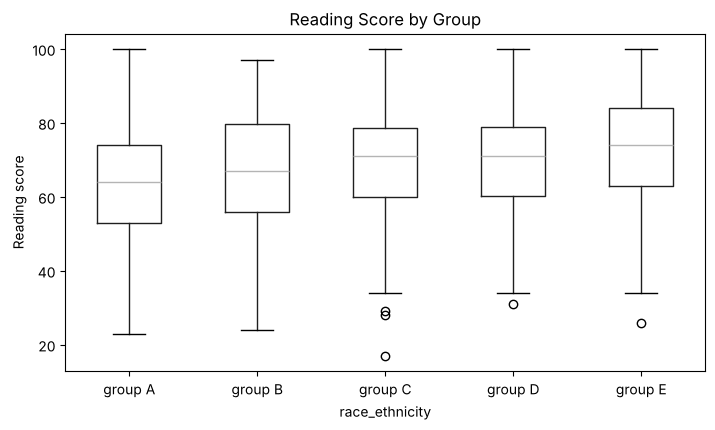

In [4]:
tukey = stats.tukey_hsd(*groups.values())
names = list(groups)
print("Pairs significantly different after Tukey HSD (p < 0.05):")
for i in range(len(names)):
    for j in range(i + 1, len(names)):
        if tukey.pvalue[i, j] < ALPHA:
            print(f"  {names[i]} vs {names[j]}: p = {tukey.pvalue[i, j]:.4f}")

students.boxplot(column="reading_score", by="race_ethnicity", figsize=(8, 4.5), grid=False)
plt.suptitle("")
plt.title("Reading Score by Group")
plt.ylabel("Reading score")
plt.savefig(FIG / "box_reading_by_group.png", dpi=120, bbox_inches="tight")
plt.show()

## Q3. Chi-square test of independence
Is gender associated with completing the test-preparation course?

Observed counts:
test_preparation_course  completed  none
gender                                  
female                         184   334
male                           174   308

Expected counts under independence:
test_preparation_course  completed    none
gender                                    
female                      185.44  332.56
male                        172.56  309.44

Chi-square       : 0.0155
Degrees of freedom: 1
p-value          : 0.9008
Cramer's V       : 0.0039
Decision         : FAIL TO REJECT H0 -> no significant association


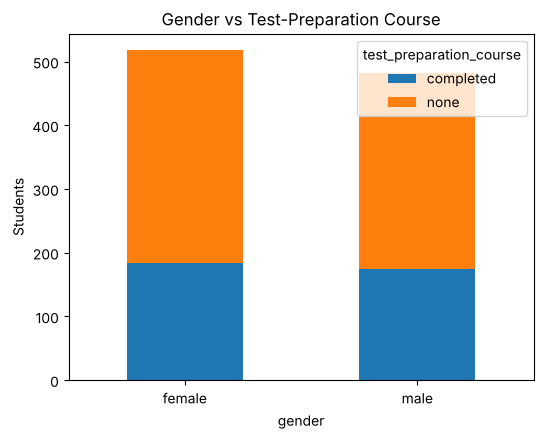

In [5]:
table = pd.crosstab(students["gender"], students["test_preparation_course"])
chi2, p3, dof, expected = stats.chi2_contingency(table)
cramers_v = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))

print("Observed counts:")
print(table.to_string())
print("\nExpected counts under independence:")
print(pd.DataFrame(expected, index=table.index, columns=table.columns).round(2).to_string())
print(f"\nChi-square       : {chi2:.4f}")
print(f"Degrees of freedom: {dof}")
print(f"p-value          : {p3:.4f}")
print(f"Cramer's V       : {cramers_v:.4f}")
print("Decision         :", verdict(p3, "gender and course completion are associated", "no significant association"))

table.plot(kind="bar", stacked=True, figsize=(6, 4.5), rot=0)
plt.title("Gender vs Test-Preparation Course")
plt.ylabel("Students")
plt.savefig(FIG / "stacked_gender_prep.png", dpi=120, bbox_inches="tight")
plt.show()

## Q4. Pearson correlation
Are reading and writing scores correlated?

Pearson r        : 0.9546   (p = < 1e-300)
Spearman rho     : 0.9490   (p = < 1e-300)
Interpretation   : very strong positive relationship
Decision         : REJECT H0 -> scores are significantly correlated


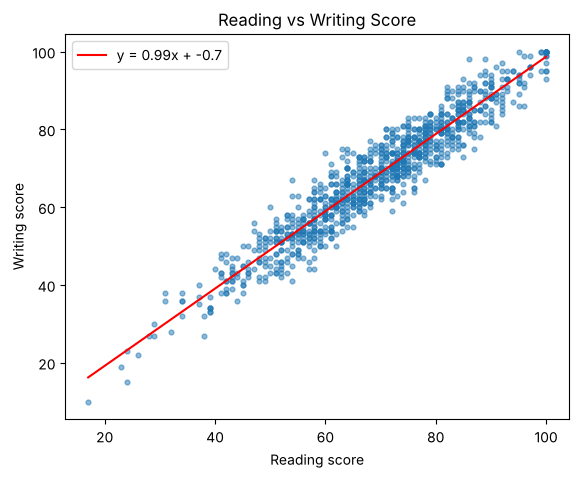

In [6]:
r, p4 = stats.pearsonr(students["reading_score"], students["writing_score"])
rho, p_rho = stats.spearmanr(students["reading_score"], students["writing_score"])
strength = ("very weak" if abs(r) < 0.2 else "weak" if abs(r) < 0.4 else
            "moderate" if abs(r) < 0.6 else "strong" if abs(r) < 0.8 else "very strong")
print(f"Pearson r        : {r:.4f}   (p = {fmt_p(p4)})")
print(f"Spearman rho     : {rho:.4f}   (p = {fmt_p(p_rho)})")
print(f"Interpretation   : {strength} {'positive' if r > 0 else 'negative'} relationship")
print("Decision         :", verdict(p4, "scores are significantly correlated", "no significant correlation"))

slope, intercept = np.polyfit(students["reading_score"], students["writing_score"], 1)
plt.figure(figsize=(6.5, 5))
plt.scatter(students["reading_score"], students["writing_score"], s=12, alpha=0.5)
xs = np.array([students["reading_score"].min(), students["reading_score"].max()])
plt.plot(xs, slope * xs + intercept, color="red", label=f"y = {slope:.2f}x + {intercept:.1f}")
plt.title("Reading vs Writing Score")
plt.xlabel("Reading score")
plt.ylabel("Writing score")
plt.legend()
plt.savefig(FIG / "scatter_reading_writing.png", dpi=120, bbox_inches="tight")
plt.show()